In [1]:
!pip -q install opencv-python-headless

import os, cv2, time, shutil
import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision import models
from PIL import Image, ImageDraw, ImageFont
from google.colab import files
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

OUTPUT_ROOT = "/content/road_issue_outputs"
IMAGE_DIR = os.path.join(OUTPUT_ROOT, "images")
VIDEO_DIR = os.path.join(OUTPUT_ROOT, "videos")
os.makedirs(IMAGE_DIR, exist_ok=True)
os.makedirs(VIDEO_DIR, exist_ok=True)

CLASS_NAMES = [
    "Broken Road Sign Issues",
    "Damaged Road issues",
    "Illegal Parking Issues",
    "Mixed Issues",
    "Pothole Issues"
]


Device: cuda


In [2]:
## 1. Upload EfficientNet-B0 weights
## Upload your EfficientNet-B0 `.pth` file. Recommended filename: `efficientnet_b0_road_model.pth` or `efficientnet_b0_best.pth`.

uploaded = files.upload()
candidates = [name for name in uploaded if "efficientnet" in name.lower() or "efficient" in name.lower()]
if not candidates:
    raise RuntimeError("Upload a .pth filename containing 'efficientnet' or 'efficient'.")
MODEL_PATH = os.path.abspath(candidates[0])
print("Using:", MODEL_PATH)

## 2. Build and load EfficientNet-B0
model = models.efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(CLASS_NAMES))

checkpoint = torch.load(MODEL_PATH, map_location="cpu", weights_only=False)
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]
if isinstance(checkpoint, dict) and any(k.startswith("module.") for k in checkpoint):
    checkpoint = {k.replace("module.", "", 1): v for k, v in checkpoint.items()}

model.load_state_dict(checkpoint, strict=True)
model = model.to(device).eval()
print("EfficientNet-B0 loaded successfully.")

MODEL_NAME = "EfficientNet-B0"


Saving efficientnet_b0_road_model.pth to efficientnet_b0_road_model.pth
Using: /content/efficientnet_b0_road_model.pth
EfficientNet-B0 loaded successfully.


In [3]:
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406),
                         std=(0.229, 0.224, 0.225))
])

def predict_image(pil_image, model):
    tensor = preprocess(pil_image.convert("RGB")).unsqueeze(0).to(device)
    with torch.inference_mode():
        with torch.autocast(device_type="cuda", dtype=torch.float16,
                            enabled=(device.type == "cuda")):
            logits = model(tensor)
            probs = torch.softmax(logits, dim=1)[0]
    idx = int(probs.argmax().item())
    return CLASS_NAMES[idx], float(probs[idx].item())

def get_font(size):
    for p in ["/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
              "/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf"]:
        if os.path.exists(p):
            return ImageFont.truetype(p, size=size)
    return ImageFont.load_default()

def annotate(pil_image, label, confidence, model_name):
    image = pil_image.convert("RGB").copy()
    draw = ImageDraw.Draw(image)
    w, h = image.size
    thickness = max(3, int(min(w, h) * 0.008))
    font = get_font(max(18, int(min(w, h) * 0.035)))
    draw.rectangle([(2, 2), (w-3, h-3)], outline=(0, 255, 0), width=thickness)
    text = f"{model_name}: {label} ({confidence*100:.1f}%)"
    box = draw.textbbox((0, 0), text, font=font)
    banner_h = min(h, box[3] - box[1] + 18)
    banner_w = min(w, box[2] - box[0] + 20)
    draw.rectangle([(0, 0), (banner_w, banner_h)], fill=(0, 110, 0))
    draw.text((8, 6), text, font=font, fill="white")
    return image

def safe_stem(filename):
    stem = os.path.splitext(os.path.basename(filename))[0]
    return "".join(c if c.isalnum() or c in "-_." else "_" for c in stem) or "input"

def process_image_file(filename, model, model_name):
    image = Image.open(filename).convert("RGB")
    label, confidence = predict_image(image, model)
    result = annotate(image, label, confidence, model_name)
    out = os.path.join(IMAGE_DIR, f"{safe_stem(filename)}_{model_name.replace('-', '').replace(' ', '')}.jpg")
    result.save(out, quality=95)
    print(f"{model_name}: {label} — {confidence*100:.2f}%")
    print("Saved:", out)
    display(result)
    return out

def process_video_file(video_path, model, model_name):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise RuntimeError("OpenCV could not open video: " + video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps <= 0 or fps > 120:
        fps = 25.0
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if width <= 0 or height <= 0:
        cap.release()
        raise RuntimeError("Could not read video dimensions.")
    out_path = os.path.join(VIDEO_DIR, f"{safe_stem(video_path)}_{model_name.replace('-', '').replace(' ', '')}_annotated.mp4")
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))
    if not writer.isOpened():
        cap.release()
        raise RuntimeError("Could not create output video.")
    count, started = 0, time.time()
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        pil = Image.fromarray(rgb)
        label, confidence = predict_image(pil, model)
        annotated = annotate(pil, label, confidence, model_name)
        writer.write(cv2.cvtColor(np.array(annotated), cv2.COLOR_RGB2BGR))
        count += 1
        if count % 100 == 0:
            print(f"{model_name}: processed {count} frames")
    cap.release()
    writer.release()
    if count == 0:
        raise RuntimeError("No frames were decoded.")
    print(f"Saved: {out_path} | Frames: {count} | Time: {time.time()-started:.1f}s")
    return out_path

def capture_webcam_snapshot(quality=0.9):
    js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const button = document.createElement('button');
      button.textContent = 'Capture photo';
      div.appendChild(button);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise(resolve => button.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks().forEach(track => track.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)
    data = eval_js(f"takePhoto({quality})")
    output = "/content/webcam_snapshot.jpg"
    with open(output, "wb") as f:
        f.write(b64decode(data.split(",")[1]))
    return output


Saving pothole.road-1.png to pothole.road-1.png
EfficientNet-B0: Pothole Issues — 96.44%
Saved: /content/road_issue_outputs/images/pothole.road-1_EfficientNetB0.jpg


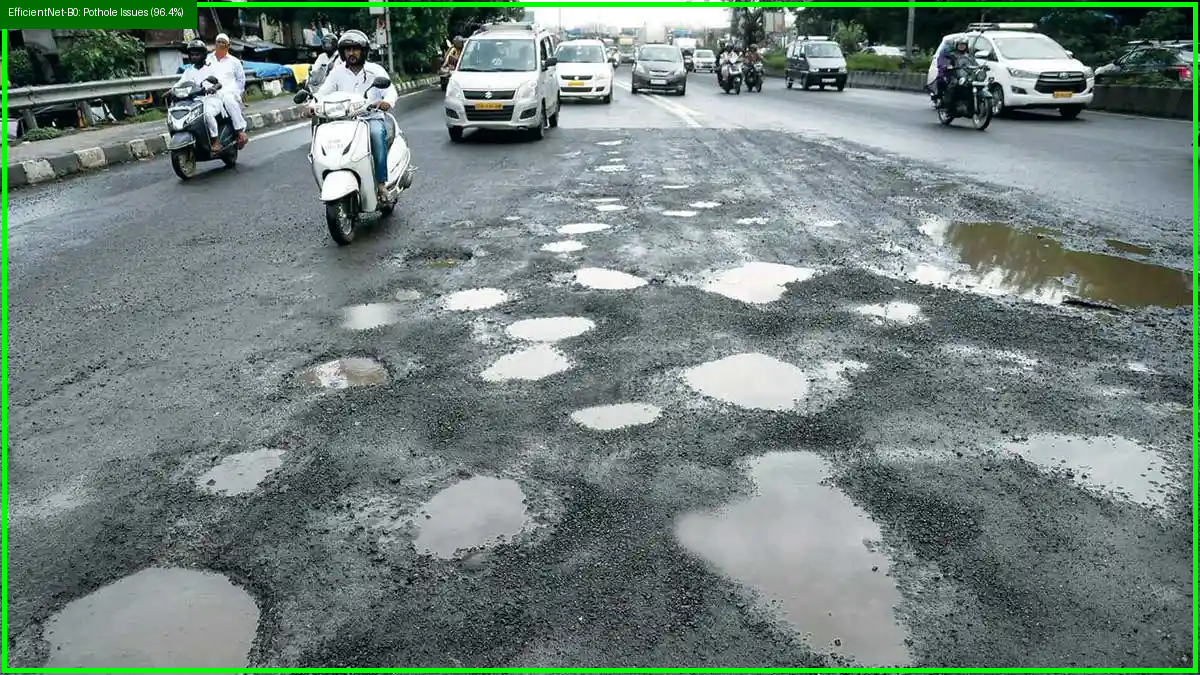

In [4]:
uploaded_images = files.upload()
for filename in uploaded_images:
    try:
        process_image_file(filename, model, MODEL_NAME)
    except Exception as exc:
        print(f"Could not process {filename}: {exc}")


In [5]:
uploaded_videos = files.upload()
for filename in uploaded_videos:
    try:
        process_video_file(filename, model, MODEL_NAME)
    except Exception as exc:
        print(f"Could not process {filename}: {exc}")


Saving Watch Video_ Terrible potholes in Rangoon Road_360p.mp4 to Watch Video_ Terrible potholes in Rangoon Road_360p.mp4
EfficientNet-B0: processed 100 frames
EfficientNet-B0: processed 200 frames
EfficientNet-B0: processed 300 frames
EfficientNet-B0: processed 400 frames
EfficientNet-B0: processed 500 frames
EfficientNet-B0: processed 600 frames
EfficientNet-B0: processed 700 frames
EfficientNet-B0: processed 800 frames
EfficientNet-B0: processed 900 frames
EfficientNet-B0: processed 1000 frames
Saved: /content/road_issue_outputs/videos/Watch_Video__Terrible_potholes_in_Rangoon_Road_360p_EfficientNetB0_annotated.mp4 | Frames: 1005 | Time: 21.1s


In [ ]:
# Uncomment to capture and process a webcam snapshot:
# webcam_path = capture_webcam_snapshot()
# process_image_file(webcam_path, model, MODEL_NAME)


In [6]:
zip_path = shutil.make_archive("/content/road_issue_outputs", "zip", OUTPUT_ROOT)
print("Created:", zip_path)
files.download(zip_path)


Created: /content/road_issue_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>